# LAB 2 · Learning from Lidar Data
**EECE 5554 · Robotics Sensing and Navigation · 10 points**

A mobile robot measures the space around it with a 2-D lidar. In this lab you work with that raw sensor data the way you would
in any machine-learning problem: **understand the data** and its noise, **fit a model** to it, **test the fit** on data it wasn't
fitted to, and **deal with bad data**. The payoff is *lidar odometry*: working out how the robot moved between two scans,
$\boldsymbol\delta = (\Delta x, \Delta y, \Delta\theta)$, from the scans alone.

**What you'll learn**
- what raw lidar data looks like, including missing returns and noise that grows with distance, and how to clean it and model its noise;
- how to fit a model to sensor data: in closed form when the model is linear, and with gradient descent when it isn't;
- how to test a fit on data it was not fitted to, and how to read its errors (residuals) against the sensor noise;
- why squared error is so sensitive to bad data, and how to deal with it: by finding and removing the bad data automatically, or with a different loss (L1).

The parts build on each other: Part 2 reuses your cleaning and noise model from Part 1, and Part 3 reuses your whole pipeline from Part 2.

**The data** (all in `data/`; each scan has 720 beams, 0.5° apart, and for every beam the lidar reports only its angle and a range. As in a ROS `LaserScan` message, a beam that got no return is reported as `inf`; the lidar's maximum range is 16 m)

| File | What the robot recorded | Used in |
|---|---|---|
| `static_scans.csv` | 100 scans taken while the robot stood still where it took scan A | Part 1 |
| `scan_A.csv` | one scan in a corridor, facing a junction (pose A) | Parts 1, 2, 3 |
| `scan_B.csv` | one scan after the robot moved into a side corridor and turned about 90° (pose B) | Parts 1, 2, 3 |
| `matcher_pairs.csv` | pairs of points that the robot's own automatic feature matcher found in scans A and B | Part 3 |

The folder next to this notebook also has `pick_landmarks.html`, a small tool you open in a web browser to pick matching points in the two scans by hand (Part 2).

**Ground rules**
- Use `numpy` and `matplotlib`. Write the least-squares solution and the gradient descent yourself. You may use `np.linalg.lstsq` only to double-check an answer.
- Structure your code however you like, and add cells as needed. Later parts reuse earlier code, so functions help.
- Keep written answers short: a few sentences each.
- Plots need axis labels with units.
- **Submit** this notebook fully executed (*Kernel → Restart & Run All*), pushed to `eece5554/LAB2/LAB2.ipynb` with `lab2_tools.py` and the `data/` folder next to it.

### Grading (10 pts)
| Part | For full credit | Pts |
|---|---|---|
| 1 · Know your lidar | missing returns counted and removed; both scans converted to x, y and plotted; noise-vs-range plot and histogram; noise model fitted in closed form and drawn on the plot; answers | 3 |
| 2 · Where did the robot go? | at least 6 well-spread pairs picked by hand; small-angle linear fit with your Part 1 closed form; loss and its gradient; gradient descent started from the linear fit, with loss curves for several learning rates; held-out error for the linear fit and gradient descent, compared with the lidar noise, with alignment plots; answers | 4 |
| 3 · When the pairs are wrong | matcher pairs fitted with your Part 2 tools; bad pairs found and removed automatically with the noise model, and refitted; L1 fit; one automatic estimator built from your functions and compared with your Part 2 answer; answers | 3 |

The bonus section at the end is optional and not graded.

---
## Setup (provided)
Run the next two cells. The first loads all the data and the helper functions from `lab2_tools.py`, which sits next to this
notebook (you don't need to open it). The second plots one raw scan.

In [1]:
import numpy as np                  
import matplotlib.pyplot as plt     
from lab2_tools import (load_scan, load_static_scans, load_pairs, show_scan, transform, transform_derivatives,
                        show_alignment, match_nearest)

A_angles, A_ranges = load_scan("scan_A.csv")                      
B_angles, B_ranges = load_scan("scan_B.csv")                      
static_angles, static_ranges = load_static_scans()                
print("one scan:", A_ranges.shape, "| static scans:", static_ranges.shape)

one scan: (720,) | static scans: (100, 720)


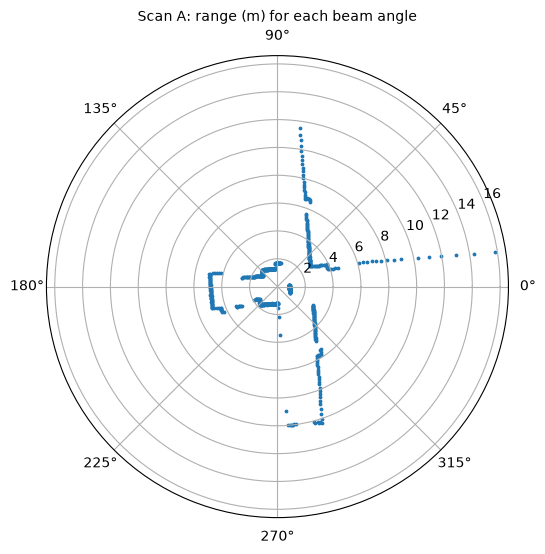

In [2]:
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": "polar"})
ok = np.isfinite(A_ranges)                                    
ax.scatter(A_angles[ok], A_ranges[ok], s=3)
ax.set_title("Scan A: range (m) for each beam angle", fontsize=10)
plt.show()

**What you're looking at.** This is exactly what the lidar reports: for each direction (0° = straight ahead of the robot), how far away
the nearest surface is. You can already see long straight walls, and some objects that stick out of them. Some directions have no dots at all:
those beams got no return, which the lidar reports as `inf`. You'll deal with them in Part 1.

### What the setup gives you
| Name | What it is / does | How you'd use it |
|---|---|---|
| `A_angles`, `A_ranges` (and `B_…`) | the raw readings of each scan: 720 beam angles (rad) and ranges (m); `inf` means no return | Part 1: clean and convert to x, y |
| `static_angles`, `static_ranges` | 100 scans from the same spot while the robot stood still; `static_ranges[i, k]` is beam *k* in scan *i* | Part 1: measure the noise |
| `show_scan(P, title, marks, zoom)` | plots x, y points `P` as the robot saw them; `marks=` draws extra points on top, `zoom=(xmin, xmax, ymin, ymax)` shows one area up close | `show_scan(scanA, "scan A")` |
| `load_pairs(name)` | reads a file of paired points; returns two (N, 2) arrays, row *j* of the first (scan A) and row *j* of the second (scan B) being the claimed same spot | Part 3: `QA, QB = load_pairs("matcher_pairs.csv")` |
| `match_nearest(P1, Q)` | pairs every point of `Q` with its closest point in `P1`; returns the indices and the distances | `idx, dist = match_nearest(scanA, Q)`; then `scanA[idx]` lines up with `Q` row by row |
| `transform(P, delta)` | **the motion model**: where scan A would see the points `P` of scan B, if the robot moved by `delta` | Parts 2–3 (explained in Part 2) |
| `transform_derivatives(P, delta)` | the partial derivatives of `transform(P, delta)` with respect to $\Delta x$, $\Delta y$ and $\Delta\theta$ | Parts 2–3: the gradient |
| `show_alignment(SA, SB, delta, title)` | overlays scan A and scan B moved with `delta`; a good estimate puts the walls on top of each other | `show_alignment(scanA, scanB, my_delta, "my estimate")` |
| `pick_landmarks.html` | not Python: a web page (open it in a browser) for picking matching points in the two scans by hand | Part 2 |

New to these tools? Start with [NumPy for absolute beginners](https://numpy.org/doc/stable/user/absolute_beginners.html),
the [Matplotlib quick start](https://matplotlib.org/stable/users/explain/quick_start.html), Python's
[functions](https://docs.python.org/3/tutorial/controlflow.html#defining-functions) and
[for loops](https://docs.python.org/3/tutorial/controlflow.html#for-statements), and
[writing math in Markdown cells](https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html).

---
## Part 1 · Know your lidar (3 pts)
Find out what's in the data, what's broken, and how noisy the sensor is.

### What to do

1. **Clean and convert.** Clean both scans, convert them to x, y points (x forward, y to the robot's left) and plot them with `show_scan`. Call the results `scanA` and `scanB`; you'll use them in every later part.
2. **Measure the noise.** `static_ranges` holds 100 scans from the same spot, so the changes between them are sensor noise. For each beam, compute the mean and the standard deviation of its range. Plot the standard deviation against the mean range, and plot a histogram of one beam's readings minus their mean, with a Gaussian of the same standard deviation on top.
3. **Fit a noise model.** Fit $\sigma = a + b \times r$ ($\sigma$: a beam's noise standard deviation, $r$: its mean range) with closed-form least squares and draw it on your plot. Write the least-squares solution as a function: Part 2 uses it again.

> **You can use:** the raw scans and `static_ranges` from the setup, `show_scan`.

> **A note on realism.** The scans in this lab are simulated, and their noise follows a deliberately simple model: independent Gaussian noise whose
> size grows with range, plus random dropouts. Real lidars are messier. Their error also depends on the surface (dark, shiny or glass), on the angle
> at which a beam hits it, and on temperature; a beam that clips an edge can return a range somewhere between the two surfaces (a "mixed pixel");
> and readings often carry a small constant bias. Treat the model you fit here as a first approximation. The bonus section points to how real
> lidar noise is modelled.

missing: 22 27
missing angles A (deg): [  7.50001754  12.00002806  30.00001286 123.50002142 174.99998906
 203.49999841 235.00001477 277.99998163 278.5000019  279.00002217
 279.49998514 280.00000541 280.50002568 280.99998865 281.50000892
 281.99997189 282.49999216 283.00001242 283.4999754  283.99999566
 284.50001593 286.00001944]


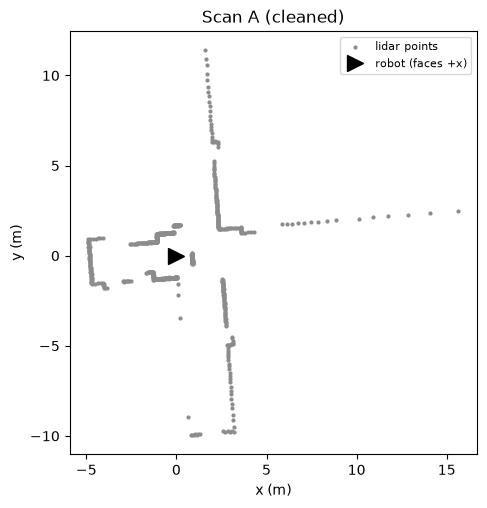

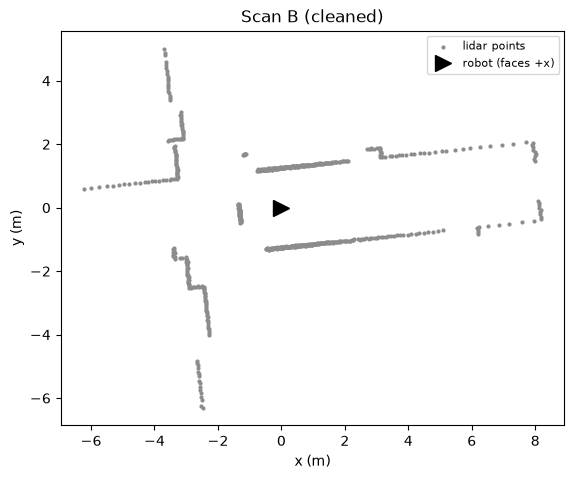

In [3]:
# Your code here
def clean_and_convert(angles, ranges):
    ok = np.isfinite(ranges)                 
    n_missing = (~ok).sum()
    a, r = angles[ok], ranges[ok]
    P = np.column_stack([r*np.cos(a), r*np.sin(a)])   
    return P, r, n_missing, angles[~ok]

scanA, rA, missA, badA = clean_and_convert(A_angles, A_ranges)
scanB, rB, missB, badB = clean_and_convert(B_angles, B_ranges)
print("missing:", missA, missB)              
print("missing angles A (deg):", np.rad2deg(badA))
show_scan(scanA, "Scan A (cleaned)")
show_scan(scanB, "Scan B (cleaned)")

In [4]:
def lstsq(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

R = np.where(np.isfinite(static_ranges), static_ranges, np.nan)   
mean_r = np.nanmean(R, axis=0)
std_r  = np.nanstd(R, axis=0)
good   = np.isfinite(R).sum(axis=0) >= 10        
print("beams used:", good.sum(), "of", len(good))

beams used: 706 of 720


C:\Users\Owner\AppData\Local\Temp\ipykernel_29004\2048294430.py:5: RuntimeWarning: Mean of empty slice
  mean_r = np.nanmean(R, axis=0)
c:\Users\Owner\.conda\envs\notebook-env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


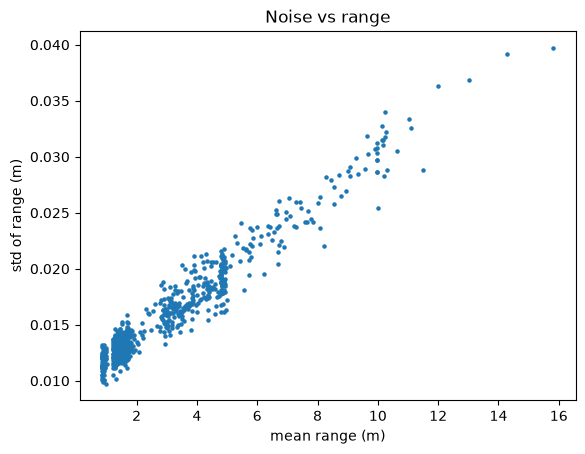

In [5]:
plt.scatter(mean_r[good], std_r[good], s=5)
plt.xlabel("mean range (m)"); plt.ylabel("std of range (m)")
plt.title("Noise vs range"); plt.show()


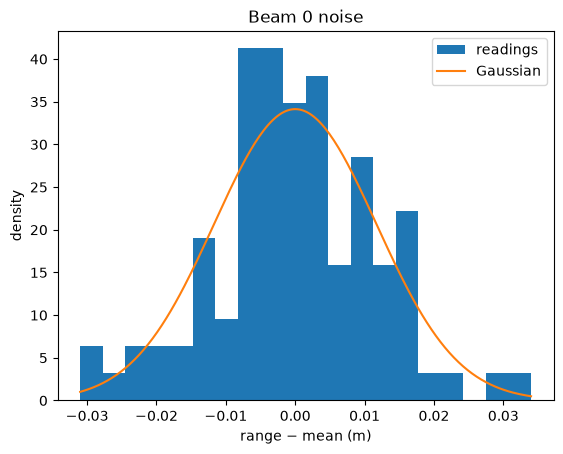

In [6]:
k = 0
dev = R[:, k][np.isfinite(R[:, k])] - mean_r[k]
s = std_r[k]; x = np.linspace(dev.min(), dev.max(), 200)
plt.hist(dev, bins=20, density=True, label="readings")
plt.plot(x, np.exp(-x**2/(2*s**2))/(s*np.sqrt(2*np.pi)), label="Gaussian")
plt.xlabel("range − mean (m)"); plt.ylabel("density")
plt.title(f"Beam {k} noise"); plt.legend(); plt.show()

sigma(r) = 0.0099 + 0.00200 * r
numpy check: [0.00994582 0.00199944]


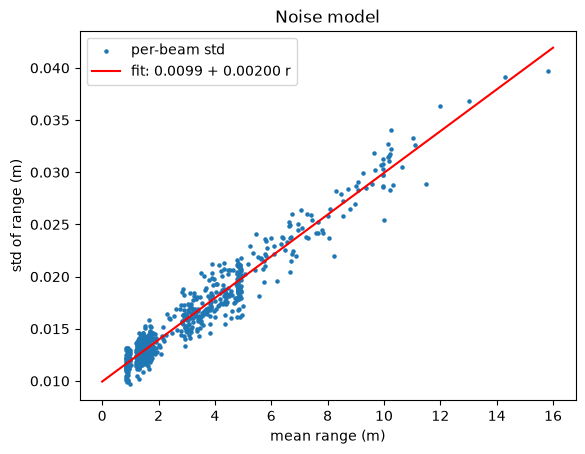

In [7]:
X = np.column_stack([np.ones(good.sum()), mean_r[good]])
a, b = lstsq(X, std_r[good])
print(f"sigma(r) = {a:.4f} + {b:.5f} * r")
print("numpy check:", np.linalg.lstsq(X, std_r[good], rcond=None)[0])

def sigma(r):
    return a + b * r

rr = np.linspace(0, 16, 100)
plt.scatter(mean_r[good], std_r[good], s=5, label="per-beam std")
plt.plot(rr, sigma(rr), "r", label=f"fit: {a:.4f} + {b:.5f} r")
plt.xlabel("mean range (m)"); plt.ylabel("std of range (m)")
plt.title("Noise model"); plt.legend(); plt.show()

### Questions
Answer in the cell below.

- **(a)** Where are the missing returns in the two scans, and what could cause them? What would go wrong if you left them in?
- **(b)** What do $a$ and $b$ mean? A datasheet promises "range noise ±(1 cm + 0.2 % of the range)". Does your lidar meet it?
- **(c)** Does the noise look Gaussian? Why does that matter for least squares?

✏️ **Your answer:**

(a) Scan A has 22 missing returns. Most of them are one contiguous block at about 278°–286° (to the robot’s right), and those beams never return in any of the 100 static scans. That points to open space beyond the 16 m maximum range, or a surface that doesn’t reflect. The rest (e.g. 7.5°, 12°, 30°, 175°) are isolated random dropouts; about 3 % of all static readings drop out. Scan B has 27 missing. Its block is at 2°–10°, straight ahead down the side corridor, again likely beyond 16 m, plus scattered single dropouts. If the inf values were left in, they would become infinite x, y points, so means, std, least-squares fits and nearest-neighbor distances would all come out as inf or nan and break.

(b) a ≈ 0.010 m is the noise floor, the noise a beam has even at zero range. b ≈ 0.0020 is how much the noise std grows per metre of range (0.2 % of range). This matches the datasheet’s 1 cm + 0.2 % almost exactly, if “±” means one standard deviation. If it meant a hard bound, the lidar would not meet it, because about 32 % of Gaussian readings fall outside ±1σ.

(c) Yes. The histogram matches the Gaussian curve; the normalized deviations have kurtosis ≈ 2.97 (a Gaussian has 3), and only about 0.26 % fall beyond 3σ (a Gaussian has 0.27 %). This matters because least squares is the maximum-likelihood estimator when the noise is Gaussian. Under that noise model, squared error is the right loss and the fit is statistically optimal.

---
## Part 2 · Where did the robot go? (4 pts)
Estimate how the robot moved between scan A and scan B: $\boldsymbol\delta = [\Delta x,\ \Delta y,\ \Delta\theta]$, how far it went forward and to its
left and how much it turned, as seen from pose A. In code, `np.array([dx, dy, dtheta])`, in metres and **radians**.

A fit needs **pairs**: the same physical spot seen in both scans. You'll pick them by hand.

### The model (given)
`transform(P, delta)` predicts where scan A sees the points `P` of scan B:

$$\hat x = x\cos\Delta\theta - y\sin\Delta\theta + \Delta x,\qquad \hat y = x\sin\Delta\theta + y\cos\Delta\theta + \Delta y.$$

For a pair, the residual is $\mathbf r = \texttt{transform}(\mathbf p_B, \boldsymbol\delta) - \mathbf p_A$, and the loss is the mean squared residual
$L(\boldsymbol\delta) = \frac1N\sum_i \left(r_{x,i}^2 + r_{y,i}^2\right)$. `transform_derivatives(P, delta)` gives the derivatives of the prediction
with respect to $\Delta x$, $\Delta y$ and $\Delta\theta$.

### What to do

1. **Pick pairs.** Open `pick_landmarks.html` in a browser, pick **at least 6 pairs spread over the scans**, press *Copy*, and paste the result into the cell below. Show your picks on both scans.
2. **Linear regression.** If the turn were small, $\cos\Delta\theta \approx 1$ and $\sin\Delta\theta \approx \Delta\theta$, and each pair would give two linear equations,
   $x_A - x_B \approx \Delta x - y_B\,\Delta\theta$ and $y_A - y_B \approx \Delta y + x_B\,\Delta\theta$. Fit them with your Part 1 least-squares function.
3. **Gradient descent.** Fit the real model by gradient descent on $L$, starting from the linear fit. Choose the learning rate and the number of iterations yourself, and plot the loss curves of the runs you tried.
4. **Held-out test.** For both fits, move all of `scanB` and compute the median distance from each moved point to its nearest point in `scanA`. Show both alignments, and compare the errors with the lidar noise your Part 1 model predicts at the scan's typical range.

Part 3 uses steps 2–4 again, so write them as functions.

> **You can use:** `scanA`, `scanB`, your least-squares function and noise model from Part 1, `match_nearest`, `transform`, `transform_derivatives`, `show_scan`, `show_alignment`.

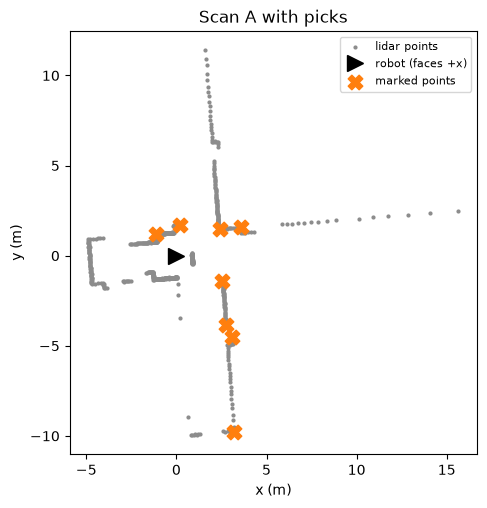

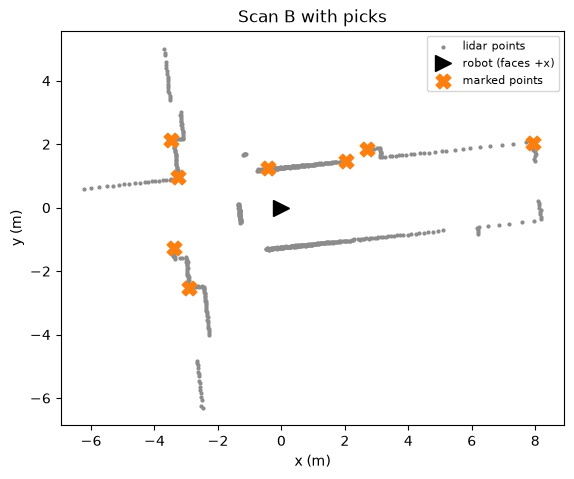

In [8]:
P1 = np.array([[3.581, 1.595], [2.416, 1.480], [0.209, 1.703], [-1.113, 1.215], [2.552, -1.415], [2.751, -3.856], [3.105, -4.517], [3.180, -9.788]])
P2 = np.array([[-3.487, 2.137], [-3.248, 0.962], [-3.389, -1.267], [-2.902, -2.522], [-0.414, 1.237], [2.030, 1.475], [2.690, 1.849], [7.926, 2.050]])
show_scan(scanA, "Scan A with picks", marks=P1)
show_scan(scanB, "Scan B with picks", marks=P2)

In [9]:
# Your code here
def build_linear(PA, PB):
    N = len(PA)
    X = np.zeros((2*N, 3)); y = np.zeros(2*N)
    X[0::2, 0] = 1; X[0::2, 2] = -PB[:, 1]; y[0::2] = PA[:, 0] - PB[:, 0]
    X[1::2, 1] = 1; X[1::2, 2] =  PB[:, 0]; y[1::2] = PA[:, 1] - PB[:, 1]
    return X, y

def linear_fit(PA, PB):
    X, y = build_linear(PA, PB)
    return lstsq(X, y)

delta_lin = linear_fit(P1, P2)
print("linear fit: dx = %.3f m, dy = %.3f m, dtheta = %.1f deg"
      % (delta_lin[0], delta_lin[1], np.rad2deg(delta_lin[2])))

X, y = build_linear(P1, P2)
print("numpy check:", np.linalg.lstsq(X, y, rcond=None)[0])   

linear fit: dx = 1.442 m, dy = -2.537 m, dtheta = -57.4 deg
numpy check: [ 1.44239131 -2.53749925 -1.00251132]


In [10]:
def l2_loss_grad(PA, PB, d):
    r = transform(PB, d) - PA                     
    D = transform_derivatives(PB, d)              
    loss = np.mean(np.sum(r**2, axis=1))
    grad = np.array([2*np.mean(np.sum(r*D[k], axis=1)) for k in range(3)])
    return loss, grad

def gd(PA, PB, d0, lr, iters, loss_grad):
    d = np.array(d0, float); L = []
    for _ in range(iters):
        l, g = loss_grad(PA, PB, d)
        L.append(l); d = d - lr * g
    return d, np.array(L)

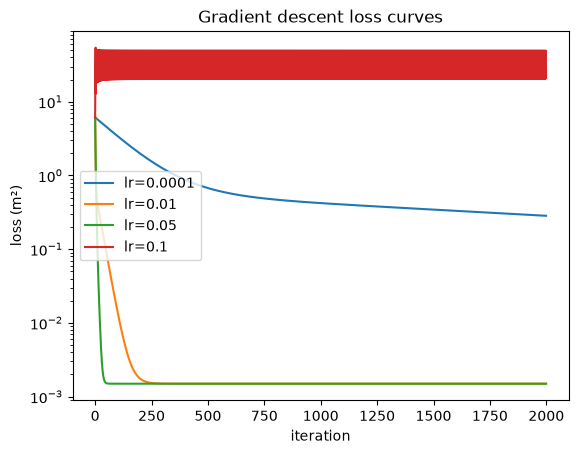

GD: dx = 1.342 m, dy = -1.774 m, dtheta = -91.8 deg


In [11]:
for lr in [0.0001, 0.01, 0.05, 0.1]:
    _, L = gd(P1, P2, delta_lin, lr, 2000, l2_loss_grad)
    plt.plot(L, label=f"lr={lr}")
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("loss (m²)")
plt.title("Gradient descent loss curves"); plt.legend(); plt.show()

delta_gd, _ = gd(P1, P2, delta_lin, 0.05, 2000, l2_loss_grad)
print("GD: dx = %.3f m, dy = %.3f m, dtheta = %.1f deg"
      % (delta_gd[0], delta_gd[1], np.rad2deg(delta_gd[2])))

In [12]:
def held_out(d):
    _, dist = match_nearest(scanA, transform(scanB, d))
    return np.median(dist)

rB_typ = np.median(np.linalg.norm(scanB, axis=1))
print("held-out  linear: %.3f m | GD: %.3f m" % (held_out(delta_lin), held_out(delta_gd)))
print("lidar sigma at typical range %.1f m: %.3f m" % (rB_typ, sigma(rB_typ)))

held-out  linear: 0.553 m | GD: 0.041 m
lidar sigma at typical range 1.8 m: 0.014 m


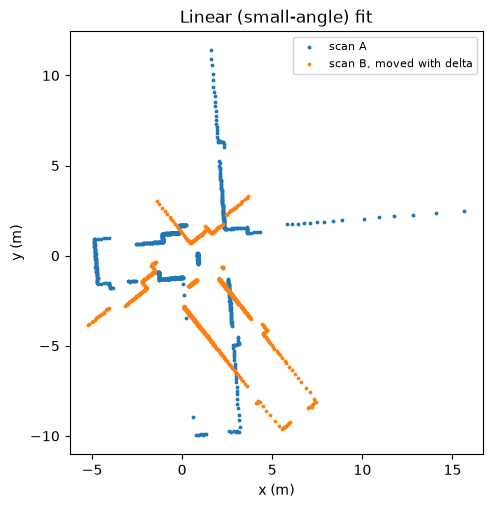

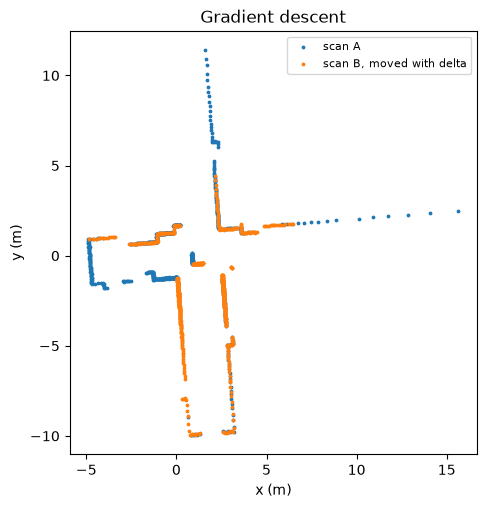

In [13]:
show_alignment(scanA, scanB, delta_lin, "Linear (small-angle) fit")
show_alignment(scanA, scanB, delta_gd, "Gradient descent")

### Questions
Answer in the cell below.

- **(a)** Why did the linear fit fail? Would more pairs fix it? When would it be good enough?
- **(b)** Which learning rates and numbers of iterations did you try? What happened when the learning rate was too small, about right and too large, and why? How did you decide the fit had converged?
- **(c)** Why test on all the scan points rather than on your pairs, and why the median? What does the comparison with the lidar noise tell you?
- **(d)** Which features were hard to pick, and why? How did you tell which feature was which?

✏️ **Your answer:**

(a) The linear fit assumes the robot turned only a little (cos θ ≈ 1, sin θ ≈ θ), but it turned about 90°. So it gave −57° instead of −92°, with a 0.55 m error. More pairs won’t help, because the model itself is wrong. It works only for small turns of a few degrees.

(b) I tried learning rates 0.0001, 0.01, 0.05 and 0.1, for 2000 iterations each. At 0.0001 the loss dropped too slowly. At 0.01–0.05 it dropped smoothly to about 0.0015 m². At 0.1 the steps overshot the minimum, and the loss jumped around without settling. I called it converged when the loss curve went flat and δ stopped changing.

(c) The pairs were used for fitting, so testing on them would make the fit look better than it is. All the scan points are a fair test. I used the median because some points in scan B have no matching wall in scan A, and the median ignores those large distances. The gradient-descent error (0.04 m) is about 3× the lidar noise (0.014 m), so the fit is good, and most of the remaining error comes from my clicking.

(d) Points on straight walls were impossible to match, so I used corners. Wall ends near gaps and far-away corners were harder, because those points are sparse or cut off. I matched features by rotating scan B 90° in my head and comparing the shapes around each corner.

---
## Part 3 · When the pairs are wrong (3 pts)
Picking by hand doesn't scale: a lidar scans ten times a second. The robot's automatic matcher paired corners in the same two scans by comparing
their surroundings. Its pairs are in `matcher_pairs.csv`, and some of them are wrong.

### What to do

1. **Fit them all** with your Part 2 functions, and compute the held-out error.
2. **Remove bad pairs automatically.** For a good pair, the residual $\|\mathbf r_i\|$ is about $\sqrt2\,\sigma(r)$, with $\sigma$ from your noise model and $r$ the point's range in scan B. Flag pairs whose residual is above $3\sqrt2\,\sigma(r)$, remove the worst flagged pair, refit, and repeat until nothing is flagged. Plot each round's residuals with the threshold, and show the removed pairs on the scans.
3. **L1 loss.** Fit all the pairs again by gradient descent on $L_1(\boldsymbol\delta) = \frac1N\sum_i \left(|r_{x,i}| + |r_{y,i}|\right)$, choosing the learning rate and iterations yourself.
4. **Put it together.** Write one automatic estimator (pairs and scans in, motion and held-out error out) and compare its answer with your Part 2 answer.

> **You can use:** `scanA`, `scanB` and your noise model from Part 1, your Part 2 functions, `load_pairs`, `transform`, `transform_derivatives`, `show_scan`, `show_alignment`.

all pairs: [ 1.56740085 -0.89124422] -83.71562514092099 deg | held-out: 0.5228032287225186


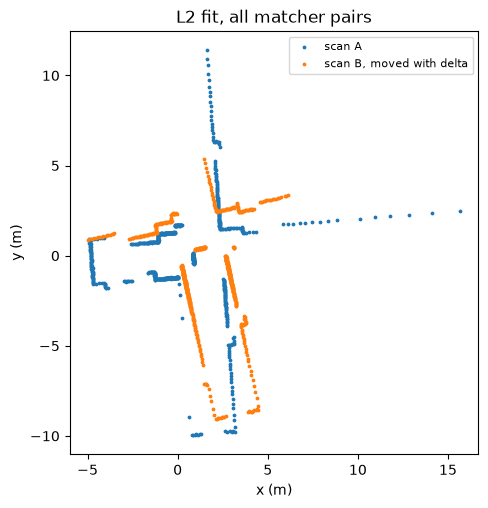

In [14]:
PA, PB = load_pairs("matcher_pairs.csv")
d_all, L = gd(PA, PB, linear_fit(PA, PB), 0.02, 3000, l2_loss_grad)
print("all pairs:", d_all[:2], np.rad2deg(d_all[2]), "deg | held-out:", held_out(d_all))
show_alignment(scanA, scanB, d_all, "L2 fit, all matcher pairs")

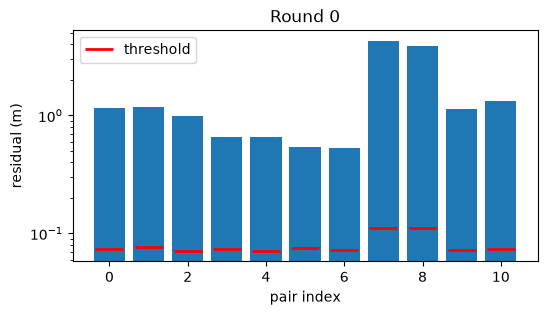

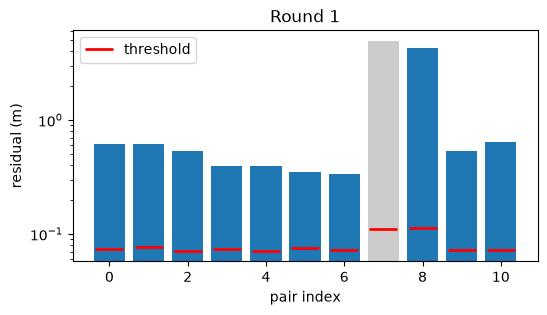

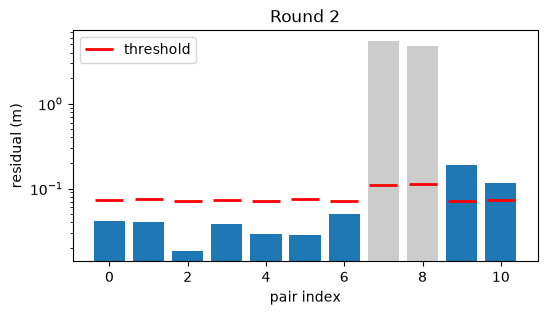

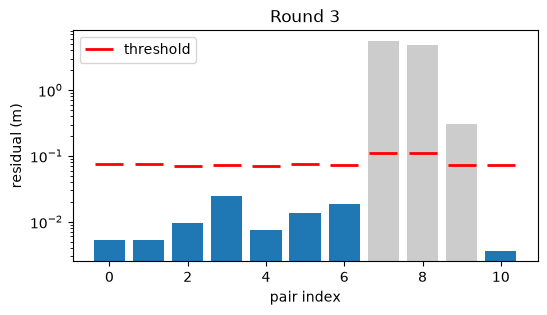

removed pairs: [7 8 9]
cleaned: [ 1.33710347 -1.75926977] -91.56527389087009 deg | held-out: 0.040922133657536275


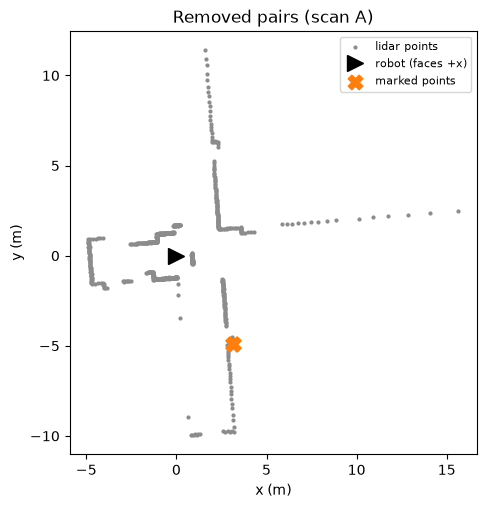

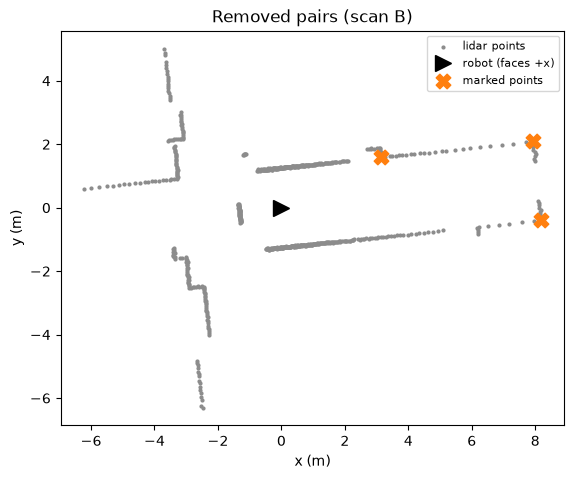

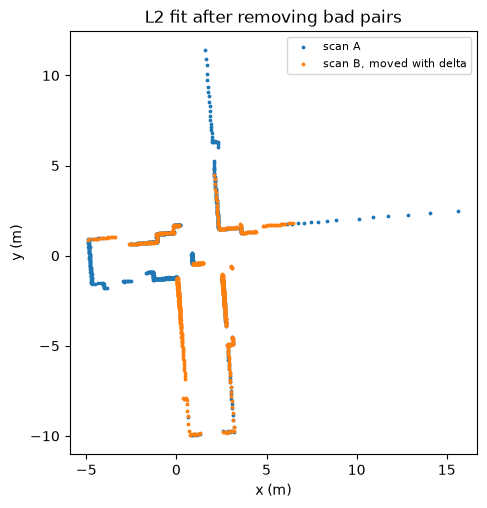

In [15]:
keep = np.ones(len(PA), bool)
rB_pairs = np.linalg.norm(PB, axis=1)            
thr = 3*np.sqrt(2)*sigma(rB_pairs)
rnd = 0
while True:
    d, _ = gd(PA[keep], PB[keep], linear_fit(PA[keep], PB[keep]), 0.02, 3000, l2_loss_grad)
    res = np.linalg.norm(transform(PB, d) - PA, axis=1)

    plt.figure(figsize=(6, 3))
    plt.bar(np.arange(len(PA)), res, color=np.where(keep, "C0", "0.8"))
    plt.plot(np.arange(len(PA)), thr, "r_", ms=20, mew=2, label="threshold")
    plt.yscale("log"); plt.xlabel("pair index"); plt.ylabel("residual (m)")
    plt.title(f"Round {rnd}"); plt.legend(); plt.show()

    flagged = keep & (res > thr)
    if not flagged.any():
        break
    worst = np.argmax(np.where(keep, res/thr, -1))  
    keep[worst] = False
    rnd += 1

d_clean = d
print("removed pairs:", np.where(~keep)[0])
print("cleaned:", d_clean[:2], np.rad2deg(d_clean[2]), "deg | held-out:", held_out(d_clean))
show_scan(scanA, "Removed pairs (scan A)", marks=PA[~keep])
show_scan(scanB, "Removed pairs (scan B)", marks=PB[~keep])
show_alignment(scanA, scanB, d_clean, "L2 fit after removing bad pairs")

lr=0.02: dtheta = -92.7 deg | held-out: 0.099 m
lr=0.005: dtheta = -91.8 deg | held-out: 0.042 m
lr=0.001: dtheta = -91.4 deg | held-out: 0.043 m


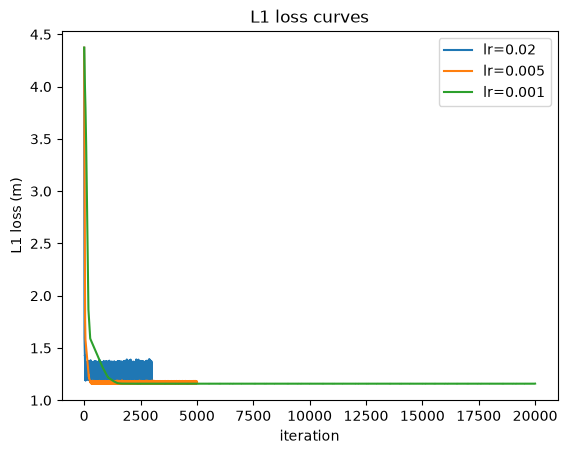

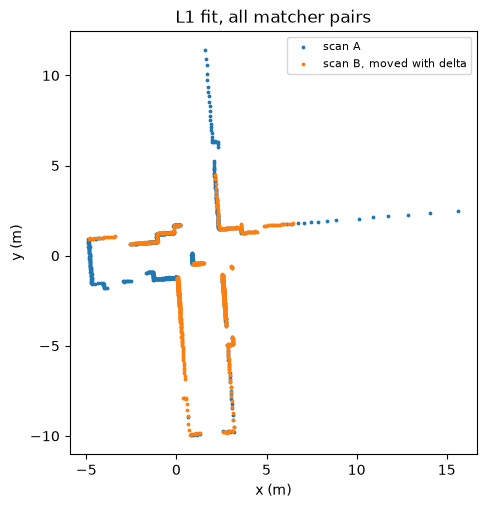

In [16]:
def l1_loss_grad(PA, PB, d):
    r = transform(PB, d) - PA
    D = transform_derivatives(PB, d)
    loss = np.mean(np.sum(np.abs(r), axis=1))
    grad = np.array([np.mean(np.sum(np.sign(r)*D[k], axis=1)) for k in range(3)])
    return loss, grad

for lr, it in [(0.02, 3000), (0.005, 5000), (0.001, 20000)]:
    d_l1, L1 = gd(PA, PB, linear_fit(PA, PB), lr, it, l1_loss_grad)
    plt.plot(L1, label=f"lr={lr}")
    print(f"lr={lr}: dtheta = {np.rad2deg(d_l1[2]):.1f} deg | held-out: {held_out(d_l1):.3f} m")
plt.xlabel("iteration"); plt.ylabel("L1 loss (m)"); plt.title("L1 loss curves")
plt.legend(); plt.show()

d_l1, _ = gd(PA, PB, linear_fit(PA, PB), 0.005, 5000, l1_loss_grad)
show_alignment(scanA, scanB, d_l1, "L1 fit, all matcher pairs")

In [17]:
def estimate_motion(PA, PB):
    keep = np.ones(len(PA), bool)
    thr = 3*np.sqrt(2)*sigma(np.linalg.norm(PB, axis=1))
    while True:
        d, _ = gd(PA[keep], PB[keep], linear_fit(PA[keep], PB[keep]), 0.02, 3000, l2_loss_grad)
        res = np.linalg.norm(transform(PB, d) - PA, axis=1)
        if not (keep & (res > thr)).any():
            return d, held_out(d), keep
        keep[np.argmax(np.where(keep, res/thr, -1))] = False

d_auto, err_auto, _ = estimate_motion(PA, PB)
print("auto:  ", d_auto[:2], np.rad2deg(d_auto[2]), "deg | held-out:", err_auto)
print("Part 2:", delta_gd[:2], np.rad2deg(delta_gd[2]), "deg | held-out:", held_out(delta_gd))

auto:   [ 1.33710347 -1.75926977] -91.56527389087009 deg | held-out: 0.040922133657536275
Part 2: [ 1.3422818  -1.77416102] -91.77432512376333 deg | held-out: 0.04053026790202249


### Questions
Answer in the cell below.

- **(a)** What do the wrong pairs have in common, and why did the matcher get them wrong? Why do a few bad pairs pull the squared-loss fit so far? Do they look like Gaussian noise?
- **(b)** Why $3\sqrt2\,\sigma(r)$? What would $1\sigma$ or $10\sigma$ do? Why remove only the worst pair each round?
- **(c)** Why is the L1 fit so much less affected? What learning rate did it need compared with Part 2, and why?
- **(d)** Remove-and-refit or L1: which would you put on a robot that runs on its own, and why?

✏️ **Your answer:**

**(a)** The three bad pairs (7, 8 and 9) all use the same corner in scan A, at (3.14, −4.91), each paired with a different corner in scan B. Many corridor corners look alike, so the matcher, which compares only the area around each corner, confused them. Squared loss makes big errors count hugely: a 5 m error counts about 60,000× more than a 2 cm error, so a few bad pairs pulled the fit from −92° to −84° (0.52 m held-out error). They are not Gaussian noise: good pairs have residuals of about 0.005–0.025 m, while the bad ones have 0.3–5.6 m, which is hundreds of σ.

**(b)** A good pair's residual combines noise in x and y, so it is about √2·σ; 3√2·σ therefore keeps almost all good pairs (like the 3σ rule) and rejects ones that are clearly wrong. At 1σ, many good pairs would be thrown out by chance. At 10σ, smaller bad pairs like pair 9 (0.30 m) would get through. I removed only the worst pair each round because one bad pair distorts the fit, which can make good pairs look bad; refitting after each removal avoids throwing out good ones.

**(c)** In L1, each pair's pull on the fit has the same size no matter how big its error is, so a few bad pairs can't dominate; the fit follows the majority, much like a median. It gave about −91.8° and 0.04 m with all 11 pairs, close to the cleaned fit. It needed a smaller learning rate (0.005, versus 0.05 in Part 2). The L1 gradient uses sign(r), so it doesn't shrink near the minimum, and with a large learning rate the fit keeps jumping back and forth instead of settling.

**(d)** I would use remove-and-refit. It uses the noise model to decide what counts as a bad pair, gives a clean least-squares answer, and reports which pairs were rejected, which is useful for checking a robot that runs on its own. Its weak point is that it starts from a fit to all pairs, so if most pairs were wrong it could fail; L1 or RANSAC would then be safer.

---
## Bonus (optional, not graded) · Further reading
Three topics that pick up where this lab stops. There is nothing to hand in; the empty cell at the end is yours to try things.

### ICP: making the pairs yourself
You fitted once, to pairs that you or the matcher made. After a fit you have a much better estimate, so you could pair again with it, fit again,
and repeat until the pairs stop changing. That loop, *guess → pair each point with its nearest neighbour → drop bad pairs → fit → repeat*, is the
**Iterative Closest Point (ICP)** algorithm, used everywhere in lidar odometry, mapping and localization. Real versions pair *every* raw point rather
than corners, measure the distance from each point to the other scan's *wall* (point-to-line or point-to-plane ICP) rather than to a single point,
solve each fit in closed form (with an SVD), and need a starting guess, from wheel odometry, an IMU or the previous motion, because they only find
the nearest good answer. Long straight corridors are a known weak spot: they look the same wherever you are along them.

### RANSAC: another way to reject bad pairs
Your remove-and-refit loop starts from a fit to *all* pairs, so it can fail when many pairs are wrong. **RANSAC** (random sample consensus) turns
this around: pick the smallest set of pairs that determines the motion (two pairs in 2-D), fit them, count how many of the other pairs agree within
the noise threshold, repeat many times, and keep the fit with the most agreement. It works even when more than half of the pairs are wrong, which is
why it is the standard first step after automatic matching, in lidar and in camera-based vision.

### How real lidar noise is modelled
The noise model in this lab is a single Gaussian per beam. A standard textbook model (the *beam model* in *Probabilistic Robotics*) treats each
reading as a mixture of four cases: a correct hit with Gaussian noise, an unexpectedly short reading (something in the way, such as a person),
a max-range reading when nothing comes back, and an occasional random reading. Sensor-characterization studies measure how the error
depends on range, surface colour and material, and the angle of incidence, and they show biases and warm-up drift that a simple model leaves out.
That mixture is also a principled reason to use robust losses like your L1.

**References**
- P. Besl and N. McKay, "A Method for Registration of 3-D Shapes," *IEEE Trans. PAMI*, 1992. The original ICP paper. [doi:10.1109/34.121791](https://doi.org/10.1109/34.121791)
- A. Censi, "An ICP Variant Using a Point-to-Line Metric," *ICRA*, 2008. ICP for 2-D lidar. [doi:10.1109/ROBOT.2008.4543181](https://doi.org/10.1109/ROBOT.2008.4543181)
- S. Rusinkiewicz and M. Levoy, "Efficient Variants of the ICP Algorithm," *3DIM*, 2001. A readable comparison of ICP's design choices. [PDF](https://graphics.stanford.edu/papers/fasticp/fasticp_paper.pdf)
- K. S. Arun, T. S. Huang, and S. D. Blostein, "Least-Squares Fitting of Two 3-D Point Sets," *IEEE Trans. PAMI*, 1987. The closed-form fit. [doi:10.1109/TPAMI.1987.4767965](https://doi.org/10.1109/TPAMI.1987.4767965)
- M. Fischler and R. Bolles, "Random Sample Consensus: A Paradigm for Model Fitting with Applications to Image Analysis and Automated Cartography," *Communications of the ACM*, 1981. The original RANSAC paper. [doi:10.1145/358669.358692](https://doi.org/10.1145/358669.358692)
- S. Thrun, W. Burgard, and D. Fox, *Probabilistic Robotics*, MIT Press, 2005. Chapter 6 covers the beam model and other lidar measurement models.
- C. Ye and J. Borenstein, "Characterization of a 2D Laser Scanner for Mobile Robot Obstacle Negotiation," *ICRA*, 2002. How a real 2-D lidar's error depends on range, surface and angle. [doi:10.1109/ROBOT.2002.1013609](https://doi.org/10.1109/ROBOT.2002.1013609)
- F. Pomerleau, F. Colas, and R. Siegwart, "A Review of Point Cloud Registration Algorithms for Mobile Robotics," *Foundations and Trends in Robotics*, 2015. [doi:10.1561/2300000035](https://doi.org/10.1561/2300000035)
- [Open3D ICP tutorial](https://www.open3d.org/docs/release/tutorial/pipelines/icp_registration.html), with code, and the [Open3D global registration tutorial](https://www.open3d.org/docs/release/tutorial/pipelines/global_registration.html) (RANSAC on feature matches).

In [18]:
# Bonus (optional): try things here.